In [1]:
runs = [7]
roll = 10
cut_off = False

In [2]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
roots = [f'/cs-data-01/drd92/pythia-vlms/{run}' for run in runs]
hparams = [json.load(open(os.path.join(root, 'hparams.json'))) for root in roots]
bses = [hparams[i]['bs'] * hparams[i]['accum'] for i in range(len(runs))]
logs = [pd.read_csv(os.path.join(root, 'log.tsv'), sep='\t') for root in roots]
if cut_off:
    last_step = min([len(log) for log in logs])
else:
    last_step = -1

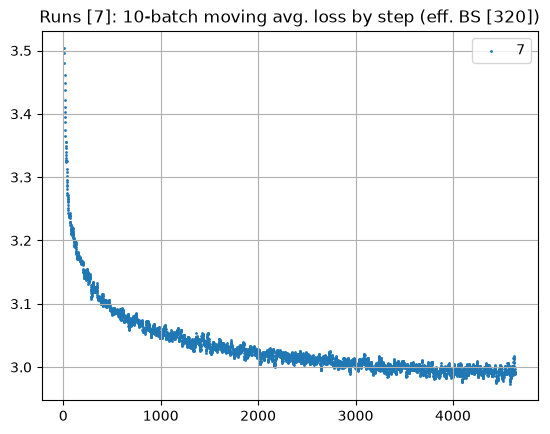

In [4]:
plt.figure()
for i in range(len(runs)):
    plt.scatter(
        logs[i]['step'][:last_step],
        logs[i]['loss'].rolling(roll).mean()[:last_step],
        s=1,
        label=str(runs[i])
    )
plt.title(f'Runs {runs}: {roll}-batch moving avg. loss by step (eff. BS {bses})')
plt.legend(loc='upper right')
plt.grid()